Printed and electronic copies of *Modeling and Simulation in Python* are available from [No Starch Press](https://nostarch.com/modeling-and-simulation-python) and [Bookshop.org](https://bookshop.org/p/books/modeling-and-simulation-in-python-allen-b-downey/17836697?ean=9781718502161) and [Amazon](https://amzn.to/3y9UxNb).

# Case Studies Part 1

*Modeling and Simulation in Python*

Copyright 2021 Allen Downey

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)

In [46]:
# download modsim.py if necessary

from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve
        local, _ = urlretrieve(url, filename)
        print('Downloaded ' + local)

download('https://raw.githubusercontent.com/AllenDowney/' +
         'ModSimPy/master/modsim.py')

In [47]:
# import functions from modsim

from modsim import *

This chapter presents case studies where you can apply the tools we have learned so far to problems involving population growth, queueing systems, and tree growth.

This chapter is available as a Jupyter notebook where you can read the text, run the code, and work on the exercises.
Click here to access the notebooks: <https://allendowney.github.io/ModSimPy/>.

## Historical World Population

The Wikipedia page about world population growth includes estimates for world population from 12,000 years ago to the present (see <https://en.wikipedia.org/wiki/World_population_estimates>).

The following cells download an archived version of this page and read the data into a Pandas `DataFrame`.

In [48]:
download('https://raw.githubusercontent.com/AllenDowney/' +
         'ModSimPy/master/data/World_population_estimates.html')

Downloaded World_population_estimates.html


In [49]:
from pandas import read_html

filename = 'World_population_estimates.html'
tables = read_html(filename, header=0, index_col=0, decimal='M')
len(tables)

6

In [50]:
table1 = tables[1]
table1.head()

,Population Reference Bureau (1973–2016)[15],United Nations Department of Economic and Social Affairs (2015)[16],Maddison (2008)[17],HYDE (2010)[citation needed],Tanton (1994)[18],Biraben (1980)[19],McEvedy & Jones (1978)[20],Thomlinson (1975)[21],Durand (1974)[22],Clark (1967)[23]
Year,,,,,,,,,,
-10000,NaN,NaN,NaN,2M[24],NaN,NaN,4.0,1–10M,NaN,NaN
-9000,NaN,NaN,NaN,4.,NaN,NaN,NaN,NaN,NaN,NaN
-8000,5.,NaN,NaN,5.,NaN,NaN,NaN,NaN,5–10M,NaN
-7000,NaN,NaN,NaN,8.,NaN,NaN,NaN,NaN,NaN,NaN
-6000,NaN,NaN,NaN,11.,NaN,NaN,NaN,NaN,NaN,NaN


Some of the values are null because not all researchers provide estimates for the same dates.

Again, we'll replace the long column names with more convenient abbreviations.

In [51]:
table1.columns = ['PRB', 'UN', 'Maddison', 'HYDE', 'Tanton',
                  'Biraben', 'McEvedy & Jones', 'Thomlinson', 'Durand', 'Clark']

Some of the estimates are in a form Pandas doesn't recognize as numbers, but we can coerce them to be numeric.

In [52]:
for col in table1.columns:
    table1[col] = pd.to_numeric(table1[col], errors='coerce')

Here are the results.  Notice that we are working in millions now, not billions.

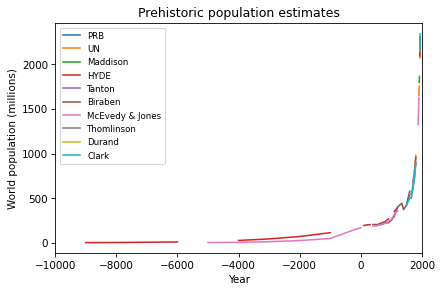

In [53]:
table1.plot()
decorate(xlim=[-10000, 2000], xlabel='Year',
         ylabel='World population (millions)',
         title='Prehistoric population estimates')
plt.legend(fontsize='small');

We can use `xlim` to zoom in on everything after Year 0.

The following figure shows the estimates of several research groups from 1 CE to the near present.

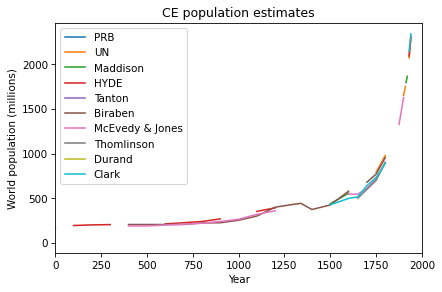

In [54]:
table1.plot()
decorate(xlim=[0, 2000], xlabel='Year',
         ylabel='World population (millions)',
         title='CE population estimates')

See if you can find a model that fits these estimates.
How well does your best model predict actual population growth from 1940 to the present?

In [55]:
tables = read_html(filename, header=0, index_col=0, decimal='M')
table2 = tables[2]
table2.columns = ['census', 'prb', 'un', 'maddison',
                  'hyde', 'tanton', 'biraben', 'mj',
                  'thomlinson', 'durand', 'clark']

In [56]:
un = table2.un / 1e9
census = table2.census / 1e9

In [57]:

# Step 1: Prepare historical population data

# Select UN historical estimates and convert millions to billions
historical = table1['UN'].dropna().astype(float) / 1000

# Sort observations by year
historical = historical.sort_index()

# Keep historical estimates up to 1940
historical = historical.loc[:1940]

# Prepare modern population data for prediction comparison
actual_un = un.dropna()
actual_census = census.dropna()

# Display historical training data
print("Historical Population Estimates (Billions)")
display(historical)

# Display data ranges
print("Historical training period:",
      historical.index.min(), "to", historical.index.max())

print("Number of historical observations:", len(historical))

print("Modern UN data:",
      actual_un.index.min(), "to", actual_un.index.max())

print("Modern Census data:",
      actual_census.index.min(), "to", actual_census.index.max())


Historical Population Estimates (Billions)


,UN
Year,
1,0.300
1000,0.310
1250,0.400
1500,0.500
1750,0.791
1800,0.978
1850,1.262
1900,1.650
1910,1.750


Historical training period: 1 to 1940
Number of historical observations: 12
Modern UN data: 1950 to 2015
Modern Census data: 1950 to 2016


Historical Model Comparison


,Historical MAE (Billions),Annual Growth,Alpha,Beta
Constant Growth,0.447409,0.000711,NaN,NaN
Proportional Growth,0.361057,NaN,0.000902,NaN
Quadratic Growth,0.362755,NaN,0.000892,0.0


Best fitting model: Proportional growth
Predicted vs Actual Population (Billions)


,Model Prediction,UN Actual,Census Actual
1950,2.321,2.525,2.558
1970,2.363,3.691,3.713
1990,2.406,5.321,5.289
2010,2.450,6.916,6.859
2015,2.461,7.349,7.248


UN prediction MAE: 2.3609
Census prediction MAE: 2.3495
2015 model prediction: 2.461 billion
2015 actual UN estimate: 7.349 billion
2015 relative error: 66.52 %


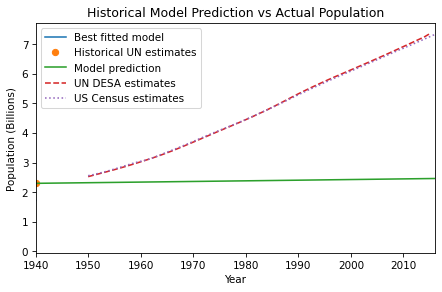

In [58]:

# Step 2: Fit population growth models and compare predictions

import pandas as pd
from numpy import linspace, mean
from modsim import System, TimeSeries

# Define the three growth functions from the course

def growth_func_constant(t, pop, system):
    return system.annual_growth


def growth_func_proportional(t, pop, system):
    return system.alpha * pop


def growth_func_quadratic(t, pop, system):
    return system.alpha * pop + system.beta * pop**2


# General simulation function based on Chapter 6

def run_population_model(system, growth_func):

    results = TimeSeries()
    results[system.t_0] = system.p_0

    for t in range(system.t_0, system.t_end):

        growth = growth_func(t, results[t], system)
        results[t + 1] = results[t] + growth

    return results


# Prepare historical observations

t0 = int(historical.index.min())
t_end = int(historical.index.max())
p0 = float(historical.loc[t0])

observed_by_year = {
    int(year): float(value)
    for year, value in historical.items()
}


# Calculate Mean Absolute Error for each candidate model

def calculate_historical_mae(model_name, parameter1, parameter2=0):

    population = p0
    errors = [abs(population - observed_by_year[t0])]

    for year in range(t0, t_end):

        if model_name == 'Constant growth':
            growth = parameter1

        elif model_name == 'Proportional growth':
            growth = parameter1 * population

        else:
            growth = (parameter1 * population
                      + parameter2 * population**2)

        population = population + growth
        next_year = year + 1

        if next_year in observed_by_year:
            errors.append(
                abs(population - observed_by_year[next_year])
            )

    return mean(errors)


# Scenario 1: Constant Growth Model (Chapter 5)

best_constant_mae = float('inf')
best_constant_growth = None

growth_values = linspace(0.0001, 0.002, 200)

for growth in growth_values:

    error = calculate_historical_mae(
        'Constant growth', growth
    )

    if error < best_constant_mae:
        best_constant_mae = error
        best_constant_growth = float(growth)


# Scenario 2: Proportional Growth Model (Chapter 6)

best_proportional_mae = float('inf')
best_alpha = None

alpha_values = linspace(0.0001, 0.002, 200)

for alpha in alpha_values:

    error = calculate_historical_mae(
        'Proportional growth', alpha
    )

    if error < best_proportional_mae:
        best_proportional_mae = error
        best_alpha = float(alpha)


# Scenario 3: Quadratic Growth Model (Chapter 7)

best_quadratic_mae = float('inf')
best_quadratic_alpha = None
best_beta = None

alpha_values = linspace(0.0001, 0.002, 61)
beta_values = linspace(-0.00008, 0.0, 41)

for alpha in alpha_values:

    for beta in beta_values:

        error = calculate_historical_mae(
            'Quadratic growth', alpha, beta
        )

        if error < best_quadratic_mae:
            best_quadratic_mae = error
            best_quadratic_alpha = float(alpha)
            best_beta = float(beta)


# Compare the historical model errors

model_comparison = pd.DataFrame({

    'Historical MAE (Billions)': [
        best_constant_mae,
        best_proportional_mae,
        best_quadratic_mae
    ],

    'Annual Growth': [
        best_constant_growth,
        None,
        None
    ],

    'Alpha': [
        None,
        best_alpha,
        best_quadratic_alpha
    ],

    'Beta': [
        None,
        None,
        best_beta
    ]

}, index=[
    'Constant Growth',
    'Proportional Growth',
    'Quadratic Growth'
])

print("Historical Model Comparison")
display(model_comparison.round(6))


# Select the model with the lowest historical MAE

model_errors = {
    'Constant growth': best_constant_mae,
    'Proportional growth': best_proportional_mae,
    'Quadratic growth': best_quadratic_mae
}

best_model_name = min(model_errors, key=model_errors.get)

print("Best fitting model:", best_model_name)


# Reconstruct the best model using its selected parameters

if best_model_name == 'Constant growth':

    historical_system = System(
        t_0=t0,
        t_end=t_end,
        p_0=p0,
        annual_growth=best_constant_growth
    )

    forecast_system = System(
        t_0=1940,
        t_end=2016,
        p_0=float(historical.loc[1940]),
        annual_growth=best_constant_growth
    )

    best_growth_function = growth_func_constant


elif best_model_name == 'Proportional growth':

    historical_system = System(
        t_0=t0,
        t_end=t_end,
        p_0=p0,
        alpha=best_alpha
    )

    forecast_system = System(
        t_0=1940,
        t_end=2016,
        p_0=float(historical.loc[1940]),
        alpha=best_alpha
    )

    best_growth_function = growth_func_proportional


else:

    historical_system = System(
        t_0=t0,
        t_end=t_end,
        p_0=p0,
        alpha=best_quadratic_alpha,
        beta=best_beta
    )

    forecast_system = System(
        t_0=1940,
        t_end=2016,
        p_0=float(historical.loc[1940]),
        alpha=best_quadratic_alpha,
        beta=best_beta
    )

    best_growth_function = growth_func_quadratic


# Run the best model on historical data

historical_model_results = run_population_model(
    historical_system,
    best_growth_function
)


# Predict population from 1940 to 2016

forecast = run_population_model(
    forecast_system,
    best_growth_function
)


# Compare predictions with actual UN and Census estimates

comparison_years = actual_un.index.intersection(
    actual_census.index
)

comparison_years = [
    int(year) for year in comparison_years
    if int(year) >= 1950
]

un_errors = [
    abs(forecast[year] - actual_un.loc[year])
    for year in comparison_years
]

census_errors = [
    abs(forecast[year] - actual_census.loc[year])
    for year in comparison_years
]

forecast_mae_un = mean(un_errors)
forecast_mae_census = mean(census_errors)


# Display selected prediction years

selected_years = [1950, 1970, 1990, 2010, 2015]

prediction_comparison = pd.DataFrame({

    'Model Prediction': [
        forecast[year] for year in selected_years
    ],

    'UN Actual': [
        actual_un.loc[year] for year in selected_years
    ],

    'Census Actual': [
        actual_census.loc[year] for year in selected_years
    ]

}, index=selected_years)

print("Predicted vs Actual Population (Billions)")
display(prediction_comparison.round(3))


# Calculate prediction error

relative_error_2015 = (
    100 * abs(forecast[2015] - actual_un.loc[2015])
    / actual_un.loc[2015]
)

print("UN prediction MAE:", round(forecast_mae_un, 4))
print("Census prediction MAE:", round(forecast_mae_census, 4))

print("2015 model prediction:", round(forecast[2015], 3), "billion")
print("2015 actual UN estimate:", round(actual_un.loc[2015], 3), "billion")
print("2015 relative error:", round(relative_error_2015, 2), "%")


# Plot 1: Historical model fit

historical_model_results.plot(
    label='Best fitted model'
)

historical.plot(
    style='o',
    label='Historical UN estimates'
)

decorate(
    xlabel='Year',
    ylabel='Population (Billions)',
    title='Best Model Fit: Historical World Population'
)


# Plot 2: Prediction compared with actual population

forecast.plot(
    label='Model prediction'
)

actual_un.plot(
    style='--',
    label='UN DESA estimates'
)

actual_census.plot(
    style=':',
    label='US Census estimates'
)

decorate(
    xlim=[1940, 2016],
    xlabel='Year',
    ylabel='Population (Billions)',
    title='Historical Model Prediction vs Actual Population'
)


In [59]:

# ============================================================
# STEP 3: GENERATE HISTORICAL WORLD POPULATION PDF REPORT
# ENG502 - CHAPTER 10
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    'historical',
    'historical_model_results',
    'actual_un',
    'actual_census',
    'forecast',
    'model_comparison',
    'prediction_comparison',
    'best_model_name',
    'best_constant_growth',
    'best_alpha',
    'best_quadratic_alpha',
    'best_beta',
    'best_constant_mae',
    'best_proportional_mae',
    'best_quadratic_mae',
    'forecast_mae_un',
    'forecast_mae_census',
    'relative_error_2015'
]

missing_variables = [
    variable for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "Please execute the second Solution cell first.\n"
        f"Missing variables: {missing_variables}"
    )


# ============================================================
# 2. MATCH MODEL NAME WITH DATAFRAME INDEX
# ============================================================

# Handle capitalization differences automatically

model_name_lookup = {
    str(name).strip().casefold(): name
    for name in model_comparison.index
}

search_name = str(best_model_name).strip().casefold()

if search_name not in model_name_lookup:
    raise ValueError(
        f"Model '{best_model_name}' was not found.\n"
        f"Available models: {list(model_comparison.index)}"
    )

best_model_label = model_name_lookup[search_name]

best_parameters = model_comparison.loc[best_model_label]

best_historical_mae = float(
    best_parameters['Historical MAE (Billions)']
)


# ============================================================
# 3. PREPARE DATA
# ============================================================

forecast_series = pd.Series(
    forecast,
    dtype=float
).sort_index()

historical_fit = pd.Series(
    historical_model_results,
    dtype=float
).sort_index()

# Convert numerical results into standard values

constant_mae = float(best_constant_mae)
proportional_mae = float(best_proportional_mae)
quadratic_mae = float(best_quadratic_mae)

prediction_2015 = float(forecast_series.loc[2015])
actual_2015 = float(actual_un.loc[2015])

prediction_error_2015 = float(relative_error_2015)

# Historical and modern data ranges

historical_start = int(historical.index.min())
historical_end = int(historical.index.max())

un_start = int(actual_un.index.min())
un_end = int(actual_un.index.max())

census_start = int(actual_census.index.min())
census_end = int(actual_census.index.max())


# ============================================================
# 4. CREATE OUTPUT FOLDER
# ============================================================

output_dir = Path(
    "Historical_World_Population_Report_Files"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

pdf_path = (
    output_dir /
    "Historical_World_Population_Report.pdf"
)


# ============================================================
# 5. EXPORT RESULT TABLES AS CSV FILES
# ============================================================

# Give proper names to DataFrame indexes

model_comparison.index.name = "Model"
prediction_comparison.index.name = "Year"

# Export model comparison

model_comparison.to_csv(
    output_dir / "Model_Comparison.csv"
)

# Export prediction comparison

prediction_comparison.to_csv(
    output_dir / "Prediction_Comparison.csv"
)

# Export complete forecast

forecast_series.to_frame(
    name="Predicted_Population_Billions"
).to_csv(
    output_dir / "Population_Forecast_1940_2016.csv"
)

# Export historical observations

historical.to_frame(
    name="Historical_UN_Population_Billions"
).to_csv(
    output_dir / "Historical_Population_Data.csv"
)


# ============================================================
# 6. GENERATE PDF REPORT
# ============================================================

with PdfPages(pdf_path) as pdf:

    # ========================================================
    # PAGE 1: TITLE AND EXECUTIVE SUMMARY
    # ========================================================

    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "HISTORICAL WORLD POPULATION",
        fontsize=21,
        fontweight="bold"
    )

    fig.text(
        0.08, 0.88,
        "ENG502 - Chapter 10 Case Study",
        fontsize=14
    )

    fig.text(
        0.08, 0.80,
        "1. Introduction and Objective",
        fontsize=15,
        fontweight="bold"
    )

    introduction = (
        "This case study investigates historical world population "
        "growth using the population estimates provided with the "
        "course material.\n\n"

        "Three mathematical growth models are implemented and "
        "compared: Constant Growth, Proportional Growth and "
        "Quadratic Growth.\n\n"

        "The models are calibrated using historical United Nations "
        "population estimates up to 1940. Their historical fitting "
        "errors are compared, and the selected model is projected "
        "forward for comparison with modern UN and US Census estimates."
    )

    fig.text(
        0.08, 0.75,
        introduction,
        fontsize=11,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.54,
        "2. Executive Summary",
        fontsize=15,
        fontweight="bold"
    )

    summary = (
        f"Best-fitting historical model: {best_model_label}\n\n"

        f"Historical MAE: "
        f"{best_historical_mae:.6f} billion\n\n"

        f"UN prediction MAE: "
        f"{forecast_mae_un:.4f} billion\n\n"

        f"Census prediction MAE: "
        f"{forecast_mae_census:.4f} billion\n\n"

        f"Predicted population in 2015: "
        f"{prediction_2015:.3f} billion\n\n"

        f"Actual UN estimate in 2015: "
        f"{actual_2015:.3f} billion\n\n"

        f"Relative prediction error in 2015: "
        f"{prediction_error_2015:.2f}%"
    )

    fig.text(
        0.08, 0.49,
        summary,
        fontsize=11,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.12,
        "Key finding: A model that fits historical population "
        "observations well does not necessarily provide accurate "
        "predictions for a later demographic period.",
        fontsize=10,
        style="italic",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)


    # ========================================================
    # PAGE 2: COURSE CONCEPTS AND METHODOLOGY
    # ========================================================

    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "3. Course Concepts and Methodology",
        fontsize=16,
        fontweight="bold"
    )

    methodology = (
        "The solution applies mathematical concepts from the "
        "provided ENG502 course chapters.\n\n"

        "SCENARIO 1: CONSTANT GROWTH MODEL\n"
        "Course Reference: Chapter 5\n\n"

        "P(t+1) = P(t) + c\n\n"

        "The model assumes that population increases by a fixed "
        "amount during each time step.\n\n"

        "SCENARIO 2: PROPORTIONAL GROWTH MODEL\n"
        "Course Reference: Chapter 6\n\n"

        "P(t+1) = P(t) + alpha * P(t)\n\n"

        "The model assumes that population growth is proportional "
        "to the current population.\n\n"

        "SCENARIO 3: QUADRATIC GROWTH MODEL\n"
        "Course Reference: Chapter 7\n\n"

        "P(t+1) = P(t) + alpha * P(t) + beta * P(t)^2\n\n"

        "The quadratic term allows the population growth rule "
        "to vary with the current population.\n\n"

        "PARAMETER SELECTION\n"
        "Course Reference: Chapter 4\n\n"

        "Parameter sweeping is used to test different parameter "
        "values and select the values that minimize historical "
        "Mean Absolute Error (MAE).\n\n"

        "DATA USED\n\n"

        f"Historical UN estimates: {historical_start}-{historical_end}\n"

        f"Historical observations: {len(historical)}\n"

        f"Modern UN data: {un_start}-{un_end}\n"

        f"Modern Census data: {census_start}-{census_end}\n\n"

        "HISTORICAL CALIBRATION VS MODERN PREDICTION\n\n"

        "Historical calibration and modern prediction are two "
        "separate simulation runs.\n\n"

        "The historical calibration starts with the year-1 UN "
        "population estimate of 0.300 billion and applies the "
        "selected growth parameters through 1940.\n\n"

        "For the modern population projection, the simulation is "
        "re-initialized using the observed 1940 UN population "
        "estimate of 2.300 billion.\n\n"

        "Therefore, the modern prediction curve does not continue "
        "directly from the historically fitted 1940 model value. "
        "The difference between these values represents the "
        "historical model fitting error at 1940 and is not a "
        "plotting error."
    )

    fig.text(
        0.08, 0.86,
        methodology,
        fontsize=9.5,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.105,
        "Out-of-Course Disclosure: Matplotlib PdfPages is used "
        "only as a technical utility to export this report. "
        "The population growth models are based on the course "
        "chapters. The nested two-parameter sweep extends the "
        "parameter-sweeping method from Chapter 4.",
        fontsize=9,
        style="italic",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)


    # ========================================================
    # PAGE 3: MODEL COMPARISON AND PREDICTION TABLES
    # ========================================================

    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "4. Scenario Results and Comparison",
        fontsize=16,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # TABLE 1: MODEL COMPARISON
    # --------------------------------------------------------

    fig.text(
        0.08, 0.86,
        "Table 1. Historical Model Fitting Results",
        fontsize=11,
        fontweight="bold"
    )

    # Correct heading: Model instead of index

    comparison_table = (
        model_comparison
        .rename_axis("Model")
        .reset_index()
        .round(6)
        .fillna("N/A")
    )

    ax1 = fig.add_axes(
        [0.05, 0.59, 0.90, 0.22]
    )

    ax1.axis("off")

    table1 = ax1.table(
        cellText=comparison_table.values,
        colLabels=comparison_table.columns,
        cellLoc="center",
        loc="center"
    )

    table1.auto_set_font_size(False)
    table1.set_fontsize(8)
    table1.scale(1, 1.7)


    # --------------------------------------------------------
    # TABLE 2: PREDICTION COMPARISON
    # --------------------------------------------------------

    fig.text(
        0.08, 0.51,
        "Table 2. Predicted Versus Actual Population",
        fontsize=11,
        fontweight="bold"
    )

    # Correct heading: Year instead of index


# Prepare prediction table with clean formatting

    prediction_table = (
        prediction_comparison
        .rename_axis("Year")
        .reset_index()
    )

    # Display years as integers
    prediction_table["Year"] = prediction_table["Year"].apply(
        lambda year: str(int(year))
    )

    # Format population values to three decimal places
    for column in [
        "Model Prediction",
        "UN Actual",
        "Census Actual"
    ]:
        prediction_table[column] = prediction_table[column].apply(
            lambda value: f"{float(value):.3f}"
        )

    ax2 = fig.add_axes([0.08, 0.33, 0.84, 0.15])
    ax2.axis("off")

    table2 = ax2.table(
        cellText=prediction_table.values,
        colLabels=prediction_table.columns,
        cellLoc="center",
        loc="center"
    )

    table2.auto_set_font_size(False)
    table2.set_fontsize(8.5)
    table2.scale(1, 1.7)



    # --------------------------------------------------------
    # INTERPRETATION
    # --------------------------------------------------------

    if abs(float(best_beta)) < 1e-10:

        beta_interpretation = (
            "The selected quadratic beta parameter is approximately "
            "zero. Therefore, the quadratic term does not provide "
            "an additional contribution in the selected solution."
        )

    else:

        beta_interpretation = (
            f"The selected quadratic beta parameter is "
            f"{float(best_beta):.6f}. This parameter modifies "
            "the growth function according to the square of "
            "the current population."
        )

    interpretation = (
        f"The model with the lowest historical MAE is "
        f"{best_model_label}, with an MAE of "
        f"{best_historical_mae:.6f} billion.\n\n"

        f"{beta_interpretation}"
    )

    fig.text(
        0.08, 0.22,
        interpretation,
        fontsize=10,
        va="top",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)


    # ========================================================
    # PAGE 4: HISTORICAL MODEL FIT GRAPH
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(8.27, 11.69)
    )

    ax.plot(
        historical_fit.index,
        historical_fit.values,
        label="Best fitted model"
    )

    ax.scatter(
        historical.index,
        historical.values,
        label="Historical UN estimates"
    )

    ax.set_title(
        "Historical Population Model Fit",
        fontsize=15
    )

    ax.set_xlabel("Year")
    ax.set_ylabel("Population (Billions)")

    ax.legend()
    ax.grid(True)

    fig.text(
        0.10, 0.07,
        "Figure 1. Historical model fit compared with the "
        "12 available UN historical population observations.",
        fontsize=10,
        wrap=True
    )

    fig.tight_layout(
        rect=[0.06, 0.12, 0.96, 0.94]
    )

    pdf.savefig(fig)

    fig.savefig(
        output_dir / "Figure_1_Historical_Model_Fit.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)


    # ========================================================
    # PAGE 5: MODERN POPULATION PREDICTION GRAPH
    # ========================================================

    fig, ax = plt.subplots(
        figsize=(8.27, 11.69)
    )

    ax.plot(
        forecast_series.index,
        forecast_series.values,
        label="Model prediction"
    )

    ax.plot(
        actual_un.index,
        actual_un.values,
        label="UN estimates"
    )

    ax.plot(
        actual_census.index,
        actual_census.values,
        label="US Census estimates"
    )

    ax.set_xlim(1940, 2016)

    ax.set_title(
        "Model Prediction versus Modern Estimates",
        fontsize=15
    )

    ax.set_xlabel("Year")
    ax.set_ylabel("Population (Billions)")

    ax.legend()
    ax.grid(True)

    fig.text(
        0.10, 0.07,
        "Figure 2. The population projection is compared with "
        "modern United Nations and US Census estimates.",
        fontsize=10,
        wrap=True
    )

    fig.tight_layout(
        rect=[0.06, 0.12, 0.96, 0.94]
    )

    pdf.savefig(fig)

    fig.savefig(
        output_dir / "Figure_2_Modern_Population_Comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)


    # ========================================================
    # PAGE 6: ANALYSIS, APPLICATIONS AND CONCLUSION
    # ========================================================

    fig = plt.figure(figsize=(8.27, 11.69))

    fig.text(
        0.08, 0.93,
        "5. Analysis, Applications and Conclusion",
        fontsize=16,
        fontweight="bold"
    )

    discussion = (
        "ANALYSIS OF RESULTS\n\n"

        f"The {best_model_label} model provides the lowest "
        f"historical fitting error, with an MAE of "
        f"{best_historical_mae:.6f} billion.\n\n"

        f"However, the model predicts a world population of "
        f"{prediction_2015:.3f} billion in 2015, compared with "
        f"the UN estimate of {actual_2015:.3f} billion. "
        f"The resulting relative prediction error is "
        f"{prediction_error_2015:.2f}%.\n\n"

        "This difference shows that historical growth patterns "
        "do not necessarily remain suitable for later demographic "
        "periods. Population growth can change due to fertility, "
        "mortality, healthcare, migration and socioeconomic conditions.\n\n"

        "REAL-WORLD APPLICATIONS\n\n"

        "Population growth models can help explain long-term "
        "demographic trends and introduce planning considerations "
        "for housing, education, healthcare and resource demand.\n\n"

        "The specific historical model fitted in this case study "
        "should not be treated as a reliable modern forecast "
        "without updated observations and recalibration.\n\n"

        "LIMITATIONS\n\n"

        "1. Historical calibration uses only 12 observations.\n"

        "2. The source does not provide annual observations "
        "for 1941-1949.\n"

        "3. The models use fixed mathematical growth rules.\n"

        "4. Fertility, mortality and migration are not modeled "
        "as separate variables.\n"

        "5. The quadratic parameter search selects beta "
        "at approximately zero.\n"

        "6. The modern prediction period is different from "
        "the historical calibration period.\n\n"

        "CONCLUSION\n\n"

        "This case study demonstrates how constant, proportional "
        "and quadratic mathematical models can be used to study "
        "population growth. The comparison also demonstrates "
        "that a model with a low historical fitting error may "
        "still produce inaccurate predictions when applied "
        "to a different period."
    )

    fig.text(
        0.08, 0.86,
        discussion,
        fontsize=10,
        va="top",
        wrap=True
    )

    fig.text(
        0.08, 0.08,
        "Source: Course-provided World_population_estimates.html "
        "historical population dataset and its UN/Census estimates.",
        fontsize=9,
        style="italic",
        wrap=True
    )

    pdf.savefig(fig)
    plt.close(fig)


# ============================================================
# 7. VALIDATE GENERATED PDF
# ============================================================

if not pdf_path.exists():
    raise FileNotFoundError(
        "PDF report was not created."
    )

if pdf_path.stat().st_size == 0:
    raise ValueError(
        "The generated PDF file is empty."
    )


# ============================================================
# 8. DISPLAY FINAL RESULTS
# ============================================================

print("=" * 60)

print("HISTORICAL WORLD POPULATION REPORT")
print("GENERATED SUCCESSFULLY")

print("=" * 60)

print("\nBest-fitting model:", best_model_label)

print(
    "Historical MAE:",
    round(best_historical_mae, 6),
    "billion"
)

print(
    "UN prediction MAE:",
    round(float(forecast_mae_un), 4),
    "billion"
)

print(
    "Census prediction MAE:",
    round(float(forecast_mae_census), 4),
    "billion"
)

print(
    "2015 predicted population:",
    round(prediction_2015, 3),
    "billion"
)

print(
    "2015 actual UN population:",
    round(actual_2015, 3),
    "billion"
)

print(
    "2015 relative error:",
    round(prediction_error_2015, 2),
    "%"
)

print("\nPDF saved at:")
print(pdf_path.resolve())

print("\nGenerated files:")

for file in sorted(output_dir.iterdir()):

    if file.is_file():

        print(
            f"{file.name} "
            f"({file.stat().st_size / 1024:.2f} KB)"
        )

print("\nReport pages: 6")
print("Model scenarios: 3")
print("CSV result files: 4")
print("Figures: 2")

print("\nAll report generation steps completed.")


HISTORICAL WORLD POPULATION REPORT
GENERATED SUCCESSFULLY

Best-fitting model: Proportional Growth
Historical MAE: 0.361057 billion
UN prediction MAE: 2.3609 billion
Census prediction MAE: 2.3495 billion
2015 predicted population: 2.461 billion
2015 actual UN population: 7.349 billion
2015 relative error: 66.52 %

PDF saved at:
/content/Historical_World_Population_Report_Files/Historical_World_Population_Report.pdf

Generated files:
Figure_1_Historical_Model_Fit.png (120.64 KB)
Figure_2_Modern_Population_Comparison.png (139.87 KB)
Historical_Population_Data.csv (0.15 KB)
Historical_World_Population_Report.pdf (62.25 KB)
Model_Comparison.csv (0.24 KB)
Population_Forecast_1940_2016.csv (1.79 KB)
Prediction_Comparison.csv (0.27 KB)

Report pages: 6
Model scenarios: 3
CSV result files: 4
Figures: 2

All report generation steps completed.


## One Queue Or Two?

This case study is related to *queueing theory*, which is the study of systems that involve waiting in lines, also known as "queues".

Suppose you are designing the checkout area for a new store. There is
enough room in the store for two checkout counters and a waiting area
for customers. You can make two lines, one for each counter, or one line that feeds both counters.

In theory, you might expect a single line to be better, but it has some practical drawbacks: in order to maintain a single line, you might have to install barriers, and customers might be put off by what seems to be a longer line, even if it moves faster.

So you'd like to check whether the single line is really better and by
how much. Simulation can help answer this question.

This figure shows the three scenarios we'll consider:

![One queue, one server (left), one queue, two servers (middle), two
queues, two servers (right).](https://github.com/AllenDowney/ModSim/raw/main/figs/queue.png)

*One queue, one server (left), one queue, two servers (middle), two
queues, two servers (right).*

As we did in the bike share model, we'll divide time into discrete time steps of one minute.
And we'll assume that a customer is equally likely to arrive during any time step.
I'll denote this probability using the Greek letter lambda, $\lambda$, or the variable name `lam`. The value of $\lambda$ probably varies from day to day, so we'll have to consider a range of possibilities.

Based on data from other stores, you know that it takes 5 minutes for a customer to check out, on average. But checkout times are variable: most customers take less than 5 minutes, but some take substantially more. A simple way to model this variability is to assume that when a customer is checking out, they always have the same probability of finishing during the next time step, regardless of how long they have been checking out. I'll denote this probability using the Greek letter mu, $\mu$, or the variable name `mu`.

If we choose $\mu=1/5$ per minute, the average time for each checkout
will be 5 minutes, which is consistent with the data. Most people take less than 5 minutes, but a few take substantially longer, which is probably not a bad model of the distribution in real stores.

Now we're ready to implement the model. In the repository for this book, you'll find a notebook called *queue.ipynb* that contains some code to get you started and instructions.
You can download it from <https://github.com/AllenDowney/ModSimPy/raw/master/examples/queue.ipynb> or run it on Colab at <https://colab.research.google.com/github/AllenDowney/ModSimPy/blob/master/examples/queue.ipynb>.

As always, you should practice incremental development: write no more
than one or two lines of code at a time, and test as you go!

## Predicting Salmon Populations

Each year the U.S. Atlantic Salmon Assessment Committee reports
estimates of salmon populations in oceans and rivers in the northeastern United States. The reports are useful for monitoring changes in these populations, but they generally do not include predictions.

The goal of this case study is to model year-to-year changes in
population, evaluate how predictable these changes are, and estimate the probability that a particular population will increase or decrease in the next 10 years.

As an example, I use data from the 2017 report, which provides population estimates for the Narraguagus and Sheepscot Rivers
in Maine.

In the repository for this book, you'll find a notebook called
*salmon.ipynb* that contains this data and some code to get you started.
You can download it from <https://github.com/AllenDowney/ModSimPy/raw/master/examples/salmon.ipynb> or run it on Colab at <https://colab.research.google.com/github/AllenDowney/ModSimPy/blob/master/examples/salmon.ipynb>.

You should take my instructions as suggestions; if you want to try
something different, please do!



## Tree Growth

This case study is based on "Height-Age Curves for Planted Stands of
Douglas Fir, with Adjustments for Density", a working paper by
Flewelling et al.
It provides *site index curves*, which are curves that show the
expected height of the tallest tree in a stand of Douglas fir as a
function of age, for a stand where the trees are the same age.
Depending on the quality of the site, the trees might grow more quickly or slowly. So each curve is identified by a *site index* that indicates the quality of the site.

The goal of this case study is to explain the shape of these
curves, that is, why trees grow the way they do.
The answer I propose involves fractal dimensions, so you might find it interesting.

In the repository for this book, you'll find a notebook called
*trees.ipynb* that incrementally develops a model of tree growth and uses it to fit the data.
You can download it from <https://github.com/AllenDowney/ModSimPy/raw/master/examples/trees.ipynb> or run it on Colab at <https://colab.research.google.com/github/AllenDowney/ModSimPy/blob/master/examples/trees.ipynb>.

There are no exercises in this case study, but it is an example of what you can do with the tools we have so far and a preview of what you will be able to do with the tools in the next few chapters.